# Sweatcoin test challenge 
Joaquin Amiel Marcora - 2023-04-23

# 0. Problem statement

**Goal**: check if users have an activity level increase after sweatcoin app installation.

The sample dataset contains daily steps of our users ( +- 2 weeks from install date):
- **user_id**: unique id of a user
- **platform**: device platform
- **reg_date**: registration date
- **steps_date**: date of steps
- **steps**: amount of steps

# 1. Read the data and import libraries

In [ ]:
pip install bayesian_testing

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from bayesian_testing.experiments import  NormalDataTest 

import statsmodels.api as sm 
import pylab as py 
import warnings
warnings.filterwarnings("ignore")
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import drive
# mount google drive information in a google colaboratory directory
drive.mount('/content/gdrive')

pd.set_option('display.max_rows', 150)


Mounted at /content/gdrive


**Please use the path to the df in your drive**

In [ ]:
path = r'gdrive/MyDrive/Data Science Project/Sweatcoin/' # insert your path

In [ ]:
df = pd.read_csv(path+'test_task.csv',parse_dates= ['reg_date','steps_date']) 
df.drop(columns= 'Unnamed: 0',inplace = True)

In [ ]:
df.head()

,user_id,platform,reg_date,steps_date,steps
0,41785284,IOS,2021-04-21,2021-04-13,458
1,41792465,IOS,2021-04-21,2021-04-13,5750
2,41494466,IOS,2021-03-28,2021-04-01,5635
3,41583452,IOS,2021-04-02,2021-04-01,1840
4,41637532,IOS,2021-04-07,2021-04-01,3127


In [ ]:
df.dtypes

user_id                int64
platform              object
reg_date      datetime64[ns]
steps_date    datetime64[ns]
steps                  int64
dtype: object

# 2. Data cleansing, preprocessing and validations

In one hand, 60.000 steps correspond to something between 60 and 70 kilometers. It is possible for a person who runs marathons, but it would be good if we investigate this data. 

In the other hand, 0 steps can happen if the user is in the hospital and he can't walk, but not in 23% of the cases, probably there was a problem in the system or the user just turn off the cellphone or left the battery charging. Records with 0 steps will be deleted in the analysis.

In [ ]:
df.describe()

,user_id,steps
count,8.154900e+04,81549.000000
mean,4.120154e+07,3933.511607
std,9.254097e+05,4826.587260
min,1.666115e+07,0.000000
25%,4.098995e+07,104.000000
50%,4.123912e+07,2187.000000
75%,4.148435e+07,6026.000000
max,4.180368e+07,60043.000000


In [ ]:
print('Percentage of records with 0 steps: ',df[df.steps==0].shape[0]/df.shape[0]*100)

Percentage of records with 0 steps:  23.0474929183681


In [ ]:
df = df[df.steps>0]

In [ ]:
print('check that there is no duplicates in the dataframe')
df.drop_duplicates(keep='last', inplace = True)

check that there is no duplicates in the dataframe


There are 5 users without a platform associated, for this reason they are going to be deleted. in the next three lines of code it can be seen that the users with platform missing present this problem in the whole window time.

In [ ]:
print('Records per platform:')
pd.value_counts(df.platform,dropna=False) 

Records per platform:


IOS        46604
ANDROID    16080
NaN           70
Name: platform, dtype: int64

In [ ]:
print('User per platform:')
df.groupby(['platform'])['user_id'].nunique()

User per platform:


platform
ANDROID    1344
IOS        2133
Name: user_id, dtype: int64

In [ ]:
user_without_platform = list(np.unique(df[df.platform.isnull()].user_id))
df[df.user_id.isin(user_without_platform) & df.platform.notnull()]

,user_id,platform,reg_date,steps_date,steps


In [ ]:
df = df[df.platform.notnull()]

In [ ]:
print('There is no user with more than one platform associated, because the maximum number of different platforms associated with one person is'
,max(df.groupby(['user_id'])['platform'].nunique().sort_values(ascending=False)),'.')

print('There is no user with more than'
, max(df.groupby(['user_id'])['steps_date'].nunique().sort_values(ascending=False))
, 'days of information (2 weeks before till 2 weeks after the installation date).')

print('However, some users have only data for',min(df.groupby(['user_id'])['steps_date'].nunique().sort_values(ascending=False)),'one day.')

There is no user with more than one platform associated, because the maximum number of different platforms associated with one person is 1 .
There is no user with more than 28 days of information (2 weeks before till 2 weeks after the installation date).
However, some users have only data for 1 one day.


Some relevant variables were created:
- **Days after reg**: the difference in days between the record date and the user instalation.
- **Sweatcoin installed**: dummy that measure if the user has the app installed when the record was registered. In this analysis is is going to be consider only users with data before and after the app install event.

In [ ]:
df['days_after_reg'] = divmod((df.steps_date - df.reg_date).dt.total_seconds(), 86400)[0]
df['sweatcoin_installed'] = np.where(df.days_after_reg >=0 , 1, 0)

df.sort_values(by=['user_id','days_after_reg'], inplace = True)

In [ ]:
data_per_user = df.groupby(['user_id']).agg({'days_after_reg': ['nunique', 'count','min','max']}).reset_index()
data_per_user.columns = ['user_id','nunique_', 'count_','min_','max_']

users = list(data_per_user[(data_per_user.min_<0) & (data_per_user.max_>=0)].user_id)

df = df[df.user_id.isin(users)]

Finally it was verified that there is no user with more than one record in one day

In [ ]:
data_per_user[(data_per_user.nunique_ < data_per_user.count_ )]

,user_id,nunique_,count_,min_,max_


From the 1.344 android user that the database has, only 161 have data before and after the app instalation event.

In [ ]:
df.groupby(['platform'])['user_id'].nunique()

platform
ANDROID     161
IOS        1695
Name: user_id, dtype: int64

# 3. Descriptive analysis

The amount of steps per days looks like a geometric distribution with an exponential decay

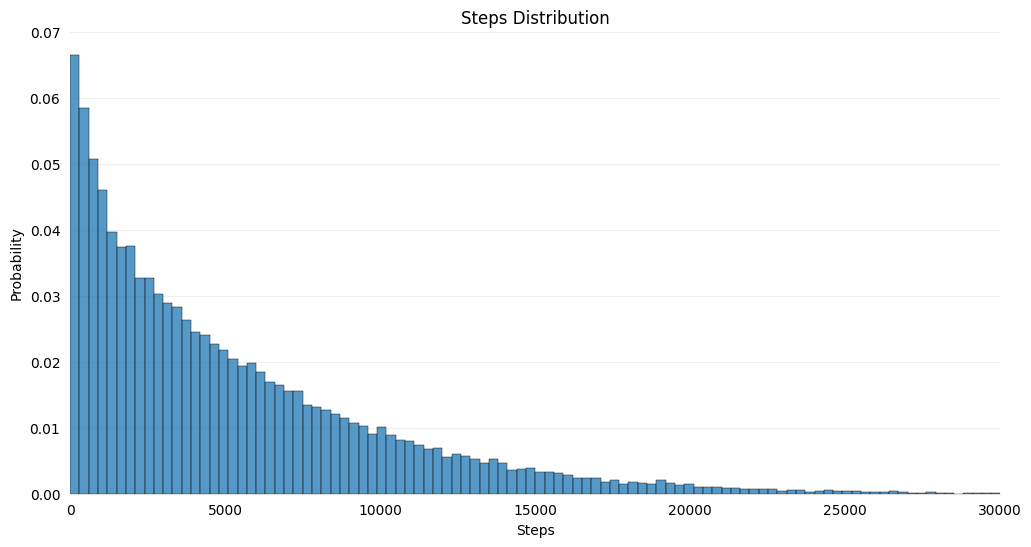

In [ ]:
plt.subplots(1, figsize=(12, 6))
ax=sns.histplot(df.steps, bins=200,stat="probability") 
ax.set_xlim(0,30000)
ax.set_ylim(0,0.07)
ax.set_title('Steps Distribution')
ax.set_xlabel('Steps')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.tick_params(bottom=False, left=False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

Looking at the following violin plot, There is an increase in the amount of step walked after the app instalation, more noticeable in the android users (in IOS is an small increment). Also, it can be observed that the median steps in the user with android is lower than the users with IOS

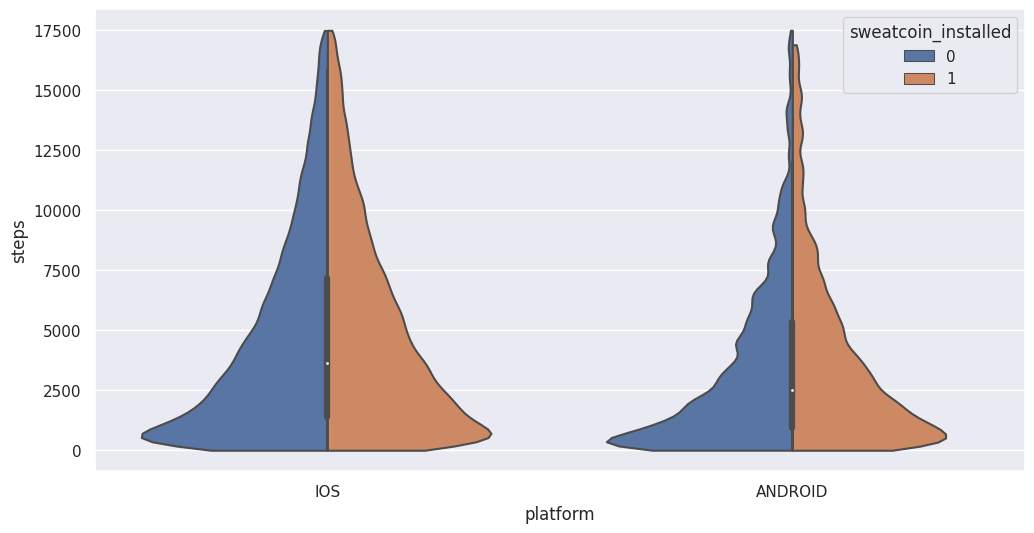

In [ ]:
sns.set(style="darkgrid")

plt.subplots(1, figsize=(12, 6))
sns.violinplot(hue="sweatcoin_installed", y="steps", data=df[df.steps<17500],  x= 'platform',split=True , cut =0, bw=.1);


It can be observed a positive correlation between the days after (or before) the app install event and the amount of steps.

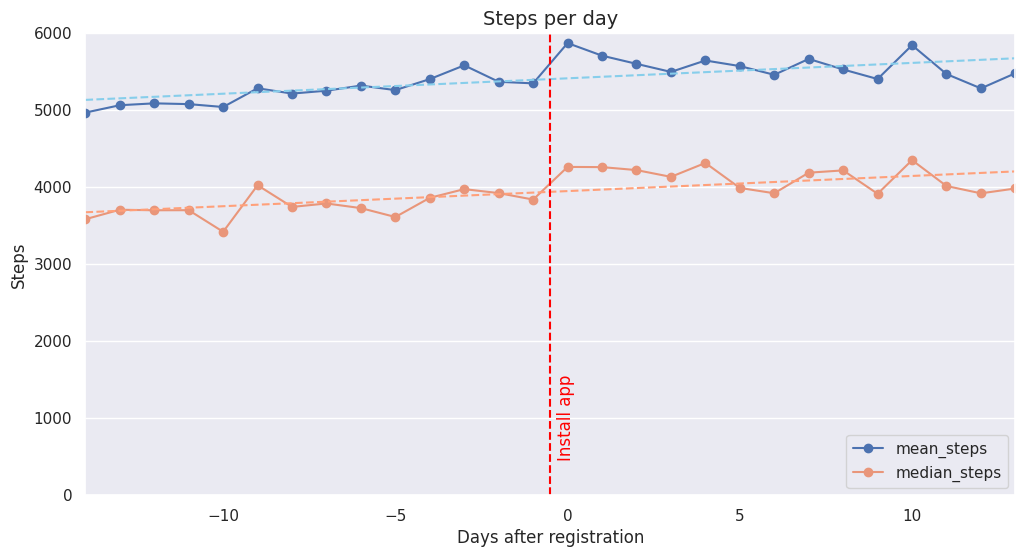

In [ ]:
#chart per day
data_chart = df[df.user_id.isin(list(data_per_user[(data_per_user.min_<-13) & (data_per_user.max_>=13)].user_id))] \
.groupby(['days_after_reg']) \
.agg({'steps': ['mean','median']}).reset_index()

data_chart.columns = ['days_after_reg','mean_steps', 'median_steps']

plt.subplots(1, figsize=(12, 6))
plt.plot('days_after_reg', 'mean_steps', data=data_chart, linestyle='-', marker='o' )

#calculate equation for trendline
z = np.polyfit(data_chart.days_after_reg, data_chart.mean_steps, 1)
p = np.poly1d(z)
#add trendline to plot
plt.plot(data_chart.days_after_reg, p(data_chart.days_after_reg), linestyle='--', color='skyblue')

plt.plot('days_after_reg', 'median_steps', data=data_chart, linestyle='-', marker='o',color = 'darksalmon')

#calculate equation for trendline
z = np.polyfit(data_chart.days_after_reg, data_chart.median_steps, 1)
p = np.poly1d(z)
#add trendline to plot
plt.plot(data_chart.days_after_reg, p(data_chart.days_after_reg), linestyle='--', color='lightsalmon')

plt.title('Steps per day', loc='center', fontsize=14, fontweight=0)
plt.grid(axis='x')
plt.xlim(-14, 13)
plt.ylim(0, 6000)
plt.axvline(x=-0.5,color='red',linestyle='--');
plt.text(-0.3,500,'Install app',rotation=90,color='red');
plt.legend(loc ="lower right")
plt.ylabel('Steps')
plt.xlabel('Days after registration');


To analyse the impact of the app installation event, it is considered the result in an user level, and measure if the user is walking more after the app installation event or not.
Moreover, a record level, is considering different weights per user because the database doesn't have the amount of step walked each day for each user and the objective is to measure a general user level of activity.

In [ ]:
bf_install = df[df.sweatcoin_installed == 0].groupby(['user_id','platform']).agg({'steps': ['mean','median']}).reset_index()
bf_install.columns = ['user_id','platform','bf_mean_steps', 'bf_median_steps']

aft_install = df[df.sweatcoin_installed == 1].groupby(['user_id']).agg({'steps': ['mean','median']}).reset_index()
aft_install.columns = ['user_id','aft_mean_steps', 'aft_median_steps']

In [ ]:
df_user = pd.merge(bf_install, aft_install,  how='left', left_on=['user_id'], right_on = ['user_id'])

From this chart, it can be compared the amount of steps before and after the app install event. If we consider as a threshold the median steps before the divide the chart in 4 quadrants, it can figure out that it looks like there is more user where the app caused a positive effect, showed in the upper left quadrant than the users that the app caused a negative effect, showed in the lower right quadrant.

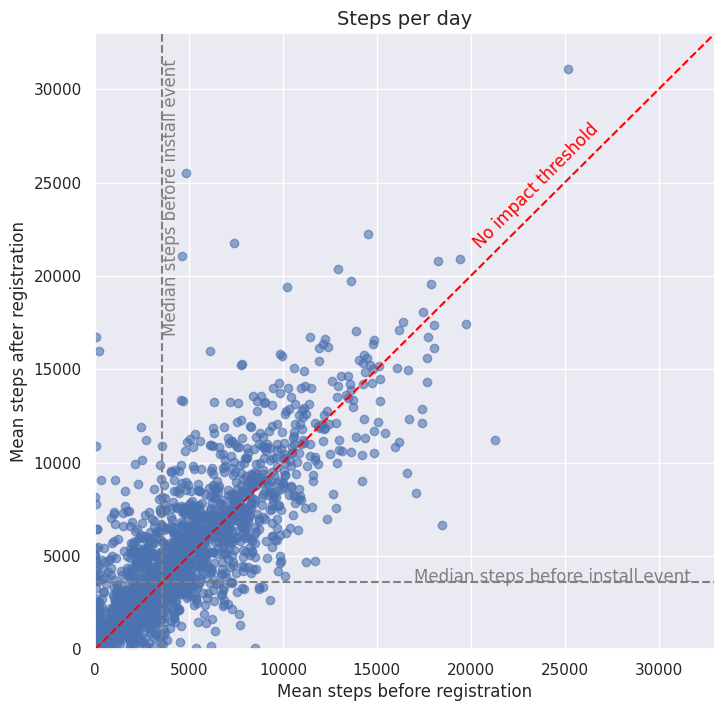

In [ ]:
plt.subplots(1, figsize=(8, 8))
plt.scatter(x=df_user.bf_mean_steps, y=df_user.aft_mean_steps , cmap="viridis", alpha=0.6)
plt.title('Steps per day', loc='center', fontsize=14, fontweight=0)
plt.xlim(0, 33000)
plt.ylim(0, 33000)

plt.axvline(x=df[df.sweatcoin_installed == 0].steps.median(),color='grey',linestyle='--');
plt.text(df[df.sweatcoin_installed == 0].steps.median(),17000,'Median steps before install event',rotation=90,color='grey');


plt.axhline(y=df.steps[df.sweatcoin_installed == 0].median(),color='grey',linestyle='--');
plt.text(17000,df.steps[df.sweatcoin_installed == 0].median(),'Median steps before install event',rotation=0,color='grey');

plt.axline([0, 0], [25000, 25000],color='red',linestyle='--')
plt.text(20000,21500,'No impact threshold',rotation=45,color='red');

plt.ylabel('Mean steps after registration')
plt.xlabel('Mean steps before registration');

In [ ]:
df_user = df_user[(df_user.bf_mean_steps<20000) & (df_user.aft_mean_steps<20000)]

To support the analysis, 2 variables were created:
- **Mean increment steps**: mean steps walked after the installation event minus mean steps walked before the installation event.
- **Positive increment steps**: a dummy variable that measure if the user walked more steps after the app installation event or not.

In [ ]:
df_user['mean_increment_steps'] = (df_user['aft_mean_steps'] - df_user['bf_mean_steps'])
df_user['positive_increment_steps'] = np.where(df_user['aft_mean_steps'] > df_user['bf_mean_steps'], 1, 0)

it can be seen than the mean increment of steps almost follow a gaussian distribution with a positive mean and median. However the distribution has some extreme values to be a normal distribution

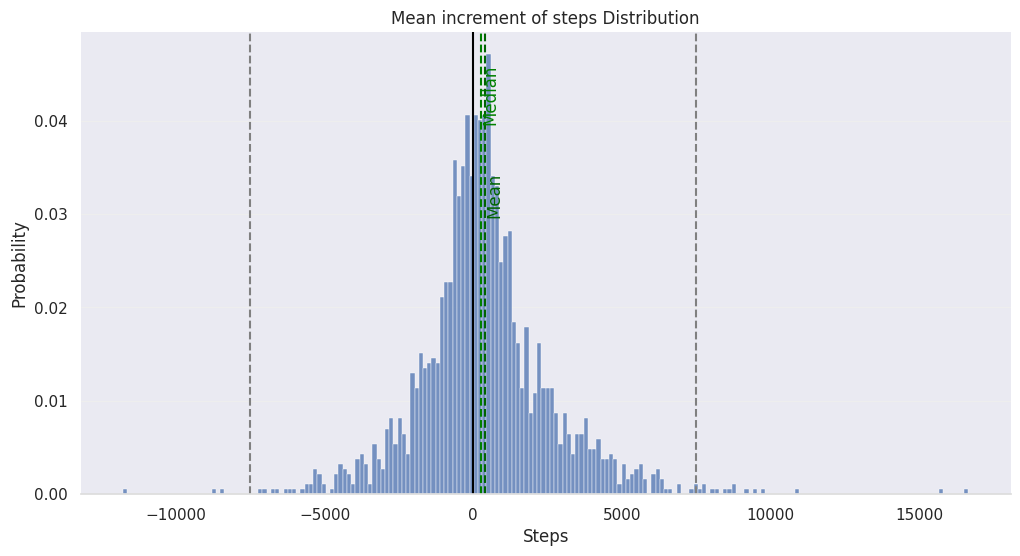

In [ ]:
plt.subplots(1, figsize=(12, 6))
ax=sns.histplot(df_user.mean_increment_steps, bins=200,stat="probability") 
ax.set_title('Mean increment of steps Distribution')
ax.set_xlabel('Steps')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.tick_params(bottom=False, left=False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

ax.axvline(x=df_user.mean_increment_steps.median(),color='green',linestyle='--');
ax.text(df_user.mean_increment_steps.median(),0.04,'Median',rotation=90,color='green');

ax.axvline(x=df_user.mean_increment_steps.mean(),color='darkgreen',linestyle='--');
ax.text(df_user.mean_increment_steps.mean(),0.03,'Mean',rotation=90,color='darkgreen');


ax.axvline(x=-7500,color='gray',linestyle='--');
ax.axvline(x=7500,color='gray',linestyle='--');

ax.axvline(x=0,color='black',linestyle='-');

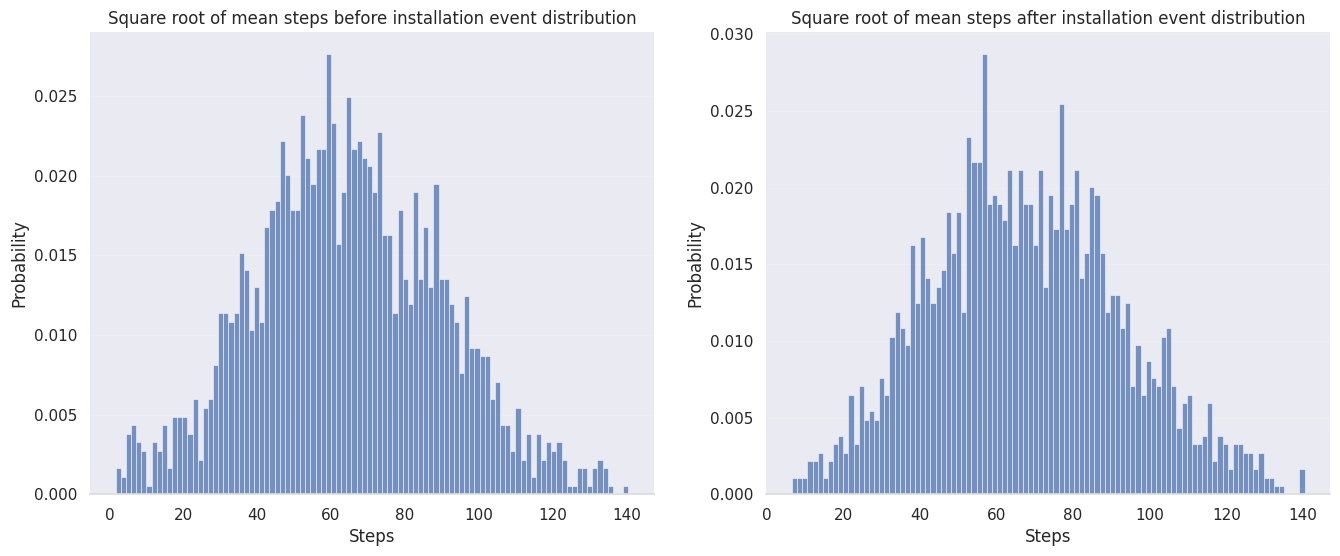

In [ ]:
f,ax=plt.subplots(figsize=(16,6))

plt.subplot(1,2, 1)
ax=sns.histplot(np.sqrt(df_user['bf_mean_steps'].values), bins=100,stat="probability") 
#ax.set_xlim(0,30000)
#ax.set_ylim(0,0.07)
ax.set_title('Square root of mean steps before installation event distribution')
ax.set_xlabel('Steps')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.tick_params(bottom=False, left=False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

plt.subplot(1,2, 2)
ax=sns.histplot(np.sqrt(df_user['aft_mean_steps'].values), bins=100,stat="probability") 
#ax.set_xlim(0,30000)
#ax.set_ylim(0,0.07)
ax.set_title('Square root of mean steps after installation event distribution')
ax.set_xlabel('Steps')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.tick_params(bottom=False, left=False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

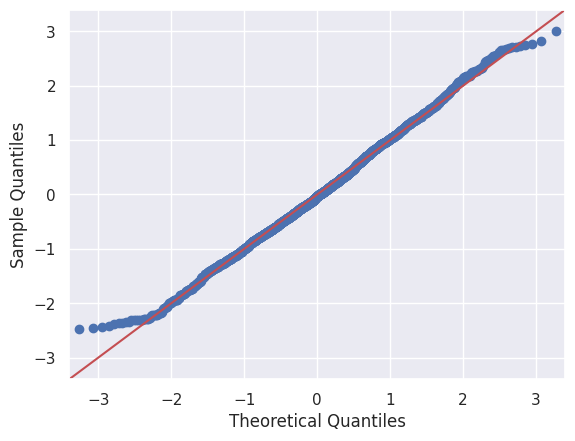

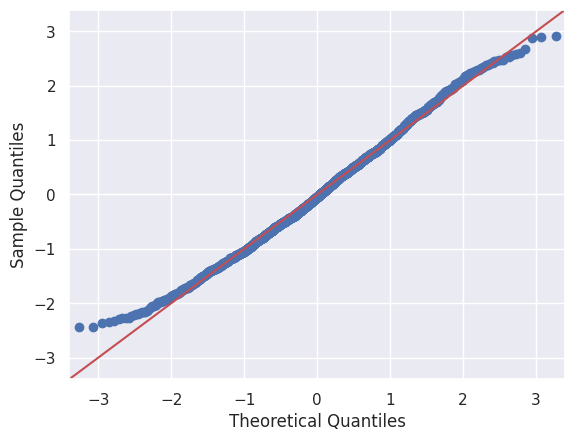

In [ ]:
y = np.sqrt(df_user['bf_mean_steps'].values)
data_points = (y -y.mean())/y.std()
  
sm.qqplot(data_points, line ='45') 
py.show() 
 
y = np.sqrt(df_user['aft_mean_steps'].values)
data_points = (y -y.mean())/y.std()
  
sm.qqplot(data_points, line ='45') 
py.show() 

57,6% of the users experimented an increase in the steps walked per day after the app installation event

In [ ]:
df_user['positive_increment_steps'].describe()

count    1847.000000
mean        0.574445
std         0.494561
min         0.000000
25%         0.000000
50%         1.000000
75%         1.000000
max         1.000000
Name: positive_increment_steps, dtype: float64

# 4. Experiments


## 4.1. Traditional Approach
First of all, it was tested that more than a half of the users have a positive change, in other words: 

- $H_0)$ $p <= 0.5$ 
- $H_1)$ $p > 0.5$ 

From the following line, the null hypothesis is rejected with a confidence of 99%, because the returned p-value is lower than the critical value of 0.01.

In [ ]:
stats.binom_test(np.sum(df_user['positive_increment_steps']), 
                 n=df_user['positive_increment_steps'].shape[0], p=0.5, alternative='greater')

8.456462424288589e-11

If we change the probability of success $p$ by 0.6, we can't reject the null hypotesis ($H_0$) $p> 0.6$.

In [ ]:
stats.binom_test(np.sum(df_user['positive_increment_steps']), 
                 n=df_user['positive_increment_steps'].shape[0], p=0.6, alternative='greater')

0.988074335850311

In second place, a paired t-test is used (also known as a dependent sample test) to compare the means of two related samples. The samples belong to the same population and are analyzed under varied conditions, e.g., at different points in time. In our case, before and after the app installation event. This test is mostly popular for pretest/posttest type of experiments where a sample is studied before and after its conditions are varied with an experiment. 

- Null Hypothesis ($H_0$): Dependent sample means ($m_1$ and $m_2$) are equal ($m_1=m_2$). In other words, the mean steps walked before the app installation is equal to the mean steps walked after the app installation event.
- Alternative Hypothesis ($H_a$): Dependent sample means ($m_1$ and $m_2$) are not equal ($m_1$!=$m_2$)

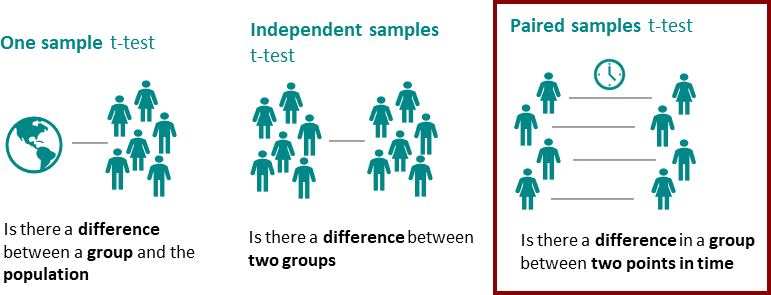

After running the paired t-test, the null hypotesis is rejected, thus there is an activity level increase after sweatcoin app installation with a 99% of confidence.

t=7.7148, p_value=0.0


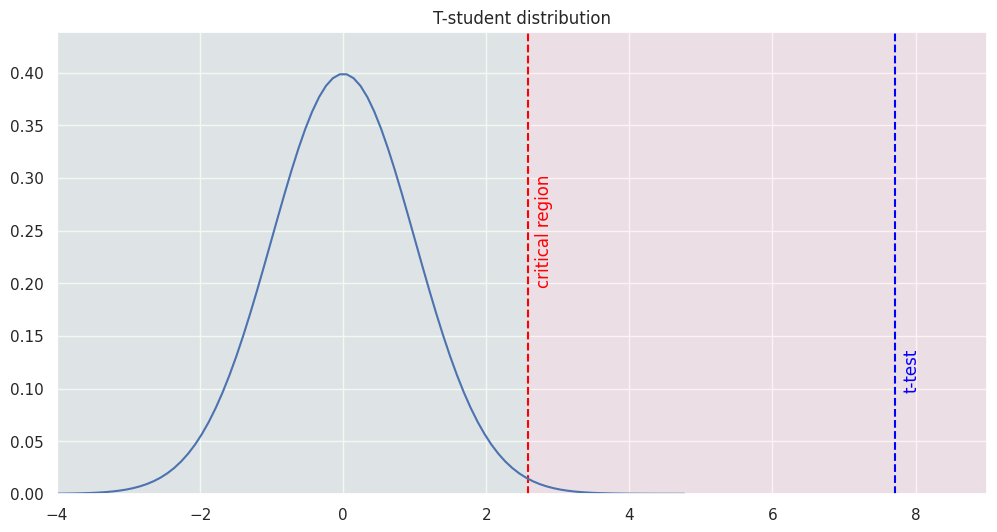

In [ ]:
dof=df_user.shape[0]-2
t_stat, p = stats.ttest_rel(np.sqrt(df_user.aft_mean_steps.values),
                            np.sqrt(df_user.bf_mean_steps.values),
                            alternative = 'greater')

print(f't={round(t_stat,4)}, p_value={round(p,4)}')
rv = stats.t(df=dof, loc=0, scale=1)
x = np.linspace(rv.ppf(0.000001), rv.ppf(0.999999), 100)
y = rv.pdf(x)

plt.subplots(1, figsize=(12, 6))

plt.axvline(x=rv.ppf(0.995),color='red',linestyle='--')
plt.text(rv.ppf(0.995)+0.1,rv.pdf(0)/2,'critical region',rotation=90,color='red')

plt.axvline(x=t_stat,color='blue',linestyle='--')
plt.text(t_stat+0.1,rv.pdf(0)/4,'t-test',rotation=90,color='blue')

plt.title('T-student distribution')
plt.xlim(-4,9)
plt.ylim(0,rv.pdf(0)*1.1)
plt.plot(x,y)

plt.axvspan(-4, rv.ppf(0.995), color='green', alpha=0.05, lw=0)
plt.axvspan( rv.ppf(0.995),9, color='red', alpha=0.05, lw=0);

## 4.2. Bayesian Approach

In certain cases, the Bayesian approach may provide useful results faster than the frequentist method. The main results are easier to understand for the business:

- **Interpretability**: Probability to chose the best variation.
- **Scalability**: Probabilities of being best scale to multiple variant tests. 

Develop a whole algorithm to use a Bayesian A/B test can be tough and prone to errors, specially in a technical test. For this reason I will use a small package for a quick evaluation of A/B (or A/B/C/...) tests using Bayesian approach. In this particular situation the data needs to have a normal distribution, for this reason square root has been used to transform the inputs. The outputs are the following:
- **Probability of being best**: probability that a given variant is best among all variants
- **Expected loss**: "risk" of choosing particular variant over other variants in the test, measured in the same units as a tested measure (e.g. positive rate or average value).

In [ ]:
test = NormalDataTest()
before_install = np.sqrt(df_user.bf_mean_steps.values)
after_install = np.sqrt(df_user.aft_mean_steps.values)

test.add_variant_data("Before app installation event", before_install)
test.add_variant_data("After app installation event", after_install)

results = test.evaluate(sim_count=100000, seed=1988, min_is_best=False)
results = pd.DataFrame(results)
results['avg_values'] = results['avg_values']**2 
results['posterior_mean'] = results['posterior_mean']**2
results['expected_loss'] = results['expected_loss']**2
results[['variant', 'avg_values', 'prob_being_best', 'expected_loss']]


,variant,avg_values,prob_being_best,expected_loss
0,Before app installation event,4150.581914,0.00004,9.835629e+00
1,After app installation event,4564.415755,0.99996,2.601000e-11


In [ ]:
test = NormalDataTest()
before_install = np.sqrt(df_user[df_user.platform == 'IOS'].bf_mean_steps.values)
after_install = np.sqrt(df_user[df_user.platform == 'IOS'].aft_mean_steps.values)

test.add_variant_data("Before app installation event - IOS", before_install)
test.add_variant_data("After app installation event - IOS", after_install)

results = test.evaluate(sim_count=100000, seed=1988, min_is_best=False)
results = pd.DataFrame(results)
results['avg_values'] = results['avg_values']**2 
results['posterior_mean'] = results['posterior_mean']**2
results['expected_loss'] = results['expected_loss']**2
results[['variant','totals', 'avg_values', 'prob_being_best', 'expected_loss']]


,variant,totals,avg_values,prob_being_best,expected_loss
0,Before app installation event - IOS,1689,4413.254469,0.01871,3.114773
1,After app installation event - IOS,1689,4649.979749,0.98129,0.000033


In [ ]:
test = NormalDataTest()
before_install = np.sqrt(df_user[df_user.platform == 'ANDROID'].bf_mean_steps.values)
after_install = np.sqrt(df_user[df_user.platform == 'ANDROID'].aft_mean_steps.values)

test.add_variant_data("Before app installation event - Android", before_install)
test.add_variant_data("After app installation event - Android", after_install)

results = test.evaluate(sim_count=100000, seed=1988, min_is_best=False)
results = pd.DataFrame(results)
results['avg_values'] = results['avg_values']**2 
results['posterior_mean'] = results['posterior_mean']**2
results['expected_loss'] = results['expected_loss']**2
results[['variant', 'totals','avg_values', 'prob_being_best', 'expected_loss']]

,variant,totals,avg_values,prob_being_best,expected_loss
0,Before app installation event - Android,158,1846.165667,0.0,318.895653
1,After app installation event - Android,158,3699.386238,1.0,0.000000


# 5. Conclusions and future steps

There is an activity level increment after Sweatcoin app installation with a probability of 99.996%, in average  the person walks 425 more steps per day (300 calories per week - 2 cans of beer). 

In the IOS users, there is an activity level increment after Sweatcoin app installation with a probability of 98.129%, in average the person walks 240 more steps per day (168 calories per week - 1 can of beer). 

It is good to mention that the users that used Android have an increment of 1.850 steps per day in average while the IOS user only 240. However, data for Android user was not the best, from the 1.344 android user that the database has, only 158 have data before and after the app instalation event.

In future steps, it would be great to have more features to test if there is an increase in the activity level in certain populations, for instance, age, sex, location, weather, user agent, source of install, etc. it will help the company to focus their campaigns in specific segments. Also it would be great if somebody analyse why so many data from android were lost.

# Biografy

- https://thedatascientist.com/how-to-do-a-t-test-in-python/
- https://towardsdatascience.com/python-package-for-bayesian-a-b-testing-86ea3ff5c963
- https://github.com/Matt52/bayesian-testing
- https://medium.com/vptech/introduction-to-bayesian-a-b-testing-in-python-df81a9b3f5fd
